1. Importa las librerías necesarias para aplicar preprocesamiento de datos,
visualización y creación de un modelo de red neuronal feedforward con Keras y
Tensorflow, además de las librerías para realizar regularización y búsqueda de grilla.
Luego, debes descartar las columnas index, arrival_date_year, agent, country,
company, reservation_status y reservation_status_date. Revisa después si la base
de datos presenta valores ausentes; en el caso que existan deberá eliminar estos
registros siempre y cuando la cantidad sea menor al 4% del total. En caso que sea
superior debes decidir si quitar la característica o imputar los datos faltantes
aplicando alguna estrategía, que debes describir.


In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import regularizers, layers
from scikeras.wrappers import KerasClassifier
import scikeras

keras.utils.set_random_seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__, '| scikeras:', scikeras.__version__)

TensorFlow: 2.21.0 | Keras: 3.15.1 | scikeras: 0.13.0


In [4]:
df = pd.read_csv('hotel_bookings.csv')
print('Dimensión original:', df.shape)

cols_descartar = ['index', 'arrival_date_year', 'agent', 'country', 'company',
                  'reservation_status', 'reservation_status_date']
df = df.drop(columns=cols_descartar)
print('Dimensión tras descartar columnas:', df.shape)

ausentes = df.isna().sum()
ausentes = ausentes[ausentes > 0]
tabla_ausentes = pd.DataFrame({
    'n_ausentes': ausentes,
    'pct_ausentes': (ausentes / len(df) * 100).round(4)
})
print('\nValores ausentes:')
print(tabla_ausentes)

if (tabla_ausentes['pct_ausentes'] < 4).all():
    df = df.dropna().reset_index(drop=True)
    print('\nTodas las variables tienen menos de 4% de ausentes: se eliminan esas filas.')
print('Dimensión tras tratar ausentes:', df.shape)

print('\nDistribución de is_canceled:')
print(pd.DataFrame({'reservas': df['is_canceled'].value_counts(),
                    'porcentaje': (df['is_canceled'].value_counts(normalize=True) * 100).round(1)}))

Dimensión original: (119390, 33)
Dimensión tras descartar columnas: (119390, 26)

Valores ausentes:
          n_ausentes  pct_ausentes
children           4        0.0034

Todas las variables tienen menos de 4% de ausentes: se eliminan esas filas.
Dimensión tras tratar ausentes: (119386, 26)

Distribución de is_canceled:
             reservas  porcentaje
is_canceled                      
0               75166        63.0
1               44220        37.0


**Observación columnas descartadas:**
- `reservation_status` y `reservation_status_date` son **fugas de información**: describen el resultado final de la reserva. `reservation_status` = "Canceled" o "No-Show" coincide exactamente con is_canceled = 1, por lo que el modelo "conocería la respuesta".
- `agent` (333 valores, 13.7% ausentes) y `company` (352 valores, 94.3% ausentes) son identificadores con muchas categorías y gran cantidad de faltantes.
- `country` tiene 177 categorías: convertirla en dummies agregaría 177 columnas muy dispersas.
- `arrival_date_year` no generaliza a reservas futuras (un modelo no puede aprender de un año que aún no ocurrió).
- `index` es solo un identificador de fila.

**Valores ausentes:** tras el descarte, solo `children` presenta ausentes (4 registros, 0.0034%), bajo el umbral de 4%, por lo que se eliminan esas filas. Quedan 119.386 reservas: 63.0% no canceladas y 37.0% canceladas. El desbalance es moderado, por lo que no se aplica balanceo y el accuracy es una métrica razonable.

2. Realiza un análisis descriptivo y prepara los datos. Para esto:
a. Selecciona 5 variables que consideres relevantes (que no sean la variable
adr) con respecto a cancelar una reserva.
b. Construye un histograma para la variable adr con reservas canceladas y no
canceladas, y comenta el resultado.
c. Revisa la presencia de outlier para la variable adr. En caso que presente
valores extremos indica la cantidad de outliers por arriba, y la cantidad de
outlier por abajo. Eliminar sólo los tres valores más extremos en ambos
casos, para los demás cambia sus valores por el valor promedio de la
variable.
d. Transforma las variables categóricas en variables dummies, estandariza las
variables independientes con media igual a cero y desviación estándar 1 y
realiza una división de los datos para entrenamiento y test, este último con un
33% de registros.


Correlación de variables numéricas con is_canceled:
lead_time                         0.293
total_of_special_requests        -0.235
required_car_parking_spaces      -0.195
booking_changes                  -0.144
previous_cancellations            0.110
is_repeated_guest                -0.085
adults                            0.060
previous_bookings_not_canceled   -0.057
days_in_waiting_list              0.054
babies                           -0.032
stays_in_week_nights              0.025
arrival_date_week_number          0.008
arrival_date_day_of_month        -0.006
children                          0.005
stays_in_weekend_nights          -0.002
dtype: float64

Diferencia entre la mayor y la menor tasa de cancelación por categoría:
deposit_type            0.771
market_segment          0.480
assigned_room_type      0.431
meal                    0.354
customer_type           0.305
distribution_channel    0.236
hotel                   0.140
reserved_room_type      0.115
arrival_date_month  

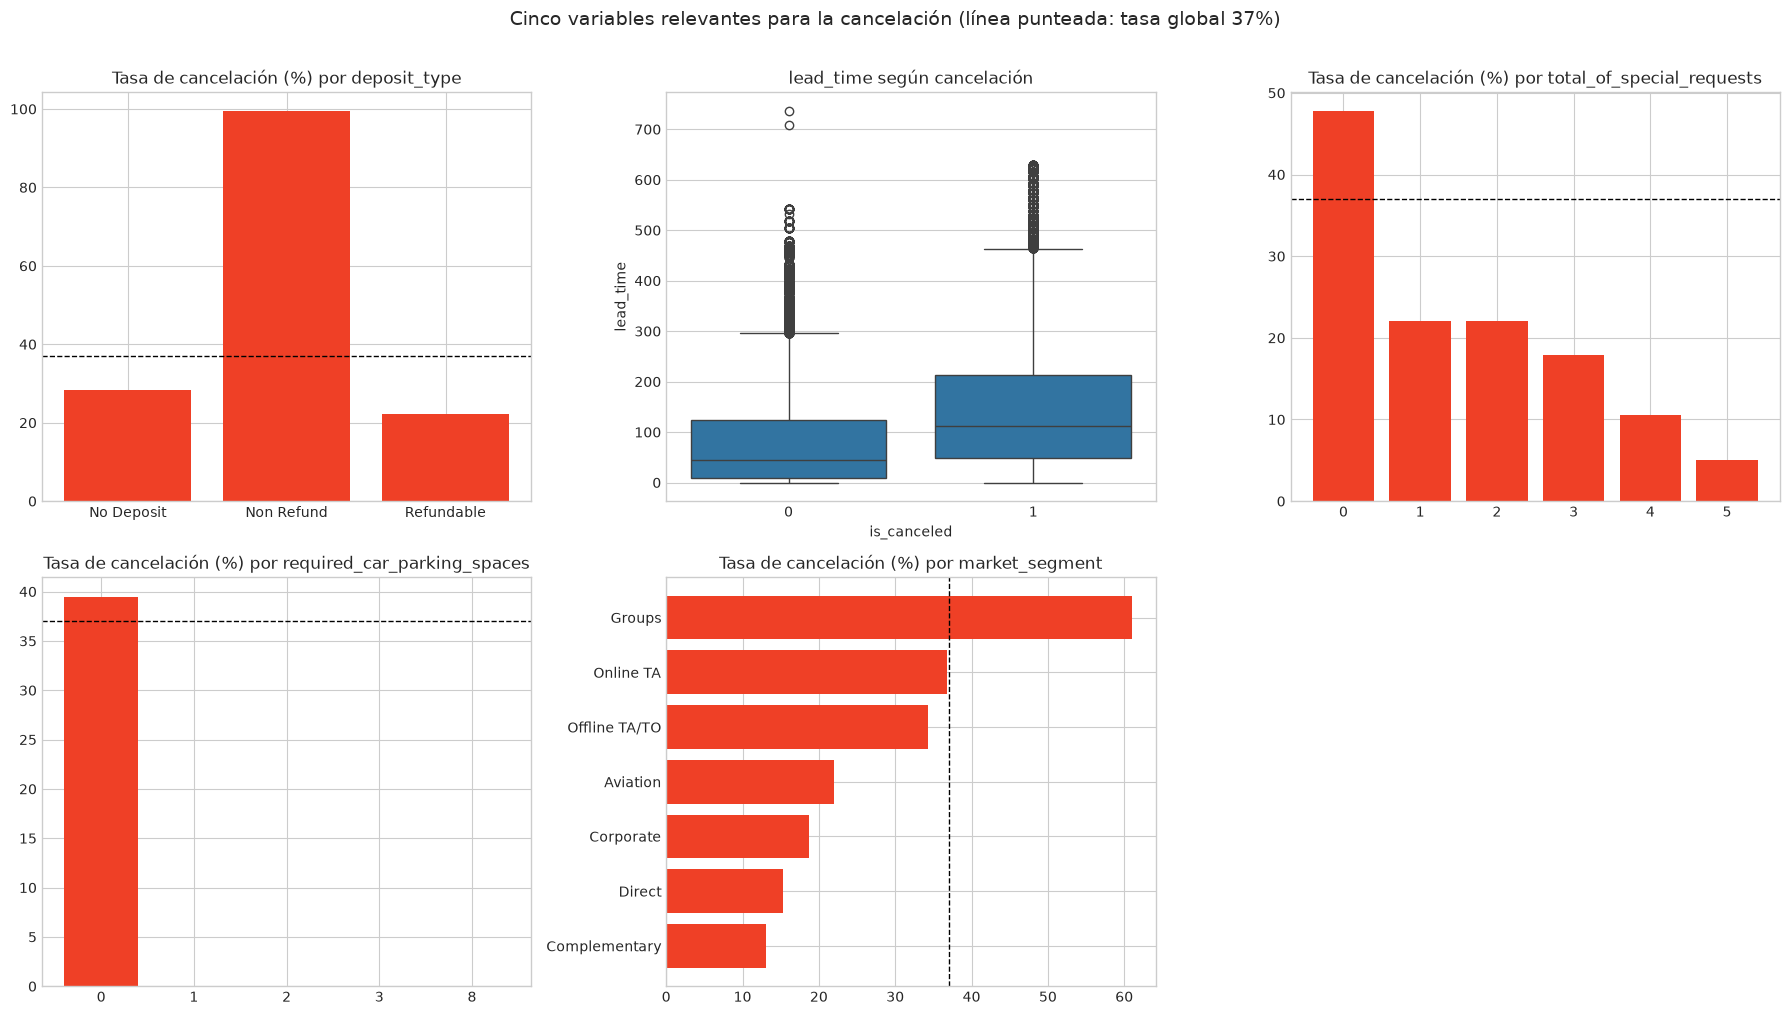

In [5]:
numericas = df.select_dtypes('number').columns.drop(['is_canceled', 'adr'])
corr_cancel = df[numericas].corrwith(df['is_canceled']).sort_values(key=abs, ascending=False)
print('Correlación de variables numéricas con is_canceled:')
print(corr_cancel.round(3))

categoricas = df.select_dtypes(exclude='number').columns
rango_tasa = {}
for c in categoricas:
    tasas = df.groupby(c)['is_canceled'].agg(['count', 'mean'])
    tasas = tasas[tasas['count'] >= 100]
    rango_tasa[c] = tasas['mean'].max() - tasas['mean'].min()
print('\nDiferencia entre la mayor y la menor tasa de cancelación por categoría:')
print(pd.Series(rango_tasa).sort_values(ascending=False).round(3))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

tasa = df.groupby('deposit_type')['is_canceled'].mean() * 100
axes[0, 0].bar(tasa.index, tasa.values, color='xkcd:tomato')
axes[0, 0].set_title('Tasa de cancelación (%) por deposit_type')

sns.boxplot(data=df, x='is_canceled', y='lead_time', ax=axes[0, 1])
axes[0, 1].set_title('lead_time según cancelación')

tasa = df.groupby('total_of_special_requests')['is_canceled'].mean() * 100
axes[0, 2].bar(tasa.index.astype(str), tasa.values, color='xkcd:tomato')
axes[0, 2].set_title('Tasa de cancelación (%) por total_of_special_requests')

tasa = df.groupby('required_car_parking_spaces')['is_canceled'].mean() * 100
axes[1, 0].bar(tasa.index.astype(str), tasa.values, color='xkcd:tomato')
axes[1, 0].set_title('Tasa de cancelación (%) por required_car_parking_spaces')

tasa = (df[df['market_segment'] != 'Undefined']
        .groupby('market_segment')['is_canceled'].mean().sort_values() * 100)
axes[1, 1].barh(tasa.index, tasa.values, color='xkcd:tomato')
axes[1, 1].set_title('Tasa de cancelación (%) por market_segment')

axes[1, 2].axis('off')
for ax in [axes[0, 0], axes[0, 2], axes[1, 0], axes[1, 1]]:
    ax.axhline(df['is_canceled'].mean() * 100, color='black', ls='--', lw=1) if ax != axes[1, 1] \
        else ax.axvline(df['is_canceled'].mean() * 100, color='black', ls='--', lw=1)

plt.suptitle('Cinco variables relevantes para la cancelación (línea punteada: tasa global 37%)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Selección de cinco variables relevantes para la cancelación

Para elegir las variables se midió su relación con is_canceled: correlación para las numéricas y diferencia entre la mayor y menor tasa de cancelación por categoría para las categóricas (considerando categorías con al menos 100 reservas). Las cinco variables seleccionadas son:

1. **deposit_type** (diferencia de tasas 0.771, la mayor del dataset): las reservas "Non Refund" cancelan el 99.4%, frente al 28.4% de "No Deposit". El resultado es contraintuitivo y podría reflejar prácticas de registro de ciertas reservas (por ejemplo, bloques de agencias).
2. **lead_time** (correlación +0.293, la mayor entre las numéricas): la mediana de anticipación es 113 días en reservas canceladas y 45 en no canceladas.
3. **total_of_special_requests** (correlación −0.235): sin peticiones especiales cancela el 47.7%; con una o más, la tasa cae a ~22% y desciende hasta 5% con cinco peticiones. Las peticiones reflejan compromiso con la estadía.
4. **required_car_parking_spaces** (correlación −0.195): ninguna de las reservas que solicitaron estacionamiento fue cancelada (0%), frente al 39.5% de las que no lo solicitaron.
5. **market_segment** (diferencia de tasas 0.480): el segmento "Groups" cancela el 61%, mientras "Direct" y "Corporate" cancelan menos del 20%.

**Advertencias:** `assigned_room_type` también separa mucho las clases (0.431), pero no se seleccionó porque la habitación se asigna al momento del check-in: las reservas canceladas casi nunca registran cambios de habitación (1.8% vs 18.8%), lo que constituye una fuga de información. Por una razón similar, el 0% de cancelación con estacionamiento solicitado podría deberse a que este dato se registra al llegar al hotel. Ambas variables se mantienen en el modelo por estar incluidas en el enunciado, pero sus efectos deben interpretarse con cautela.

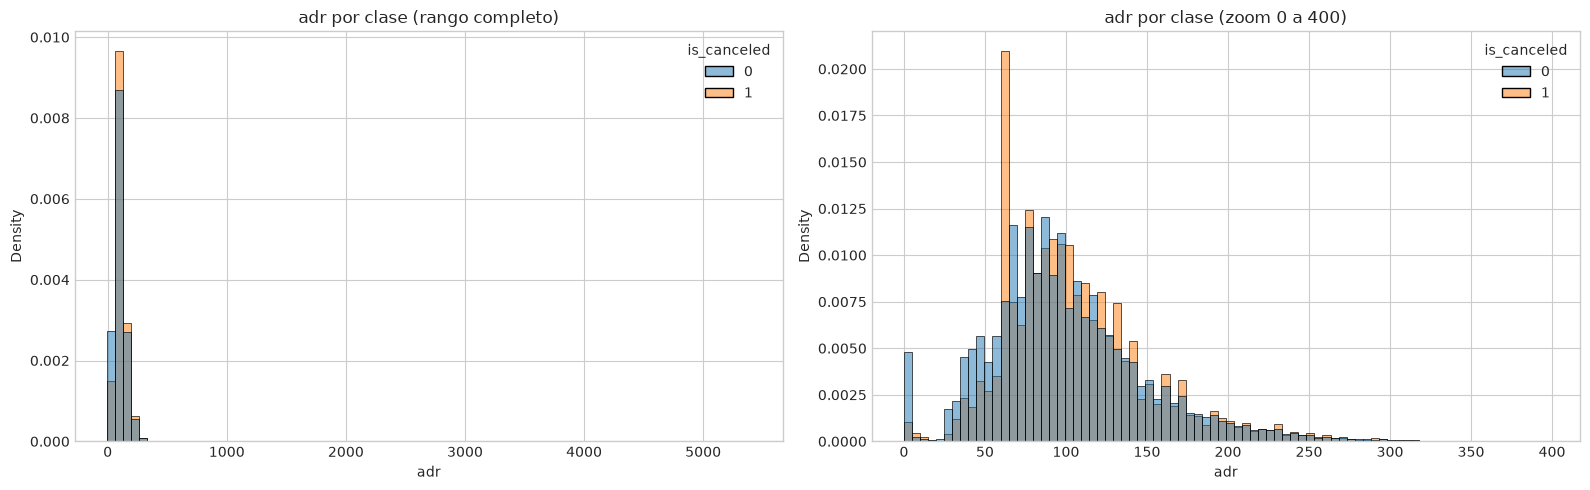

               count   mean   std  min   25%   50%    75%     max
is_canceled                                                      
0            75166.0  100.0  49.2 -6.4  67.5  92.5  125.0   510.0
1            44220.0  105.0  52.6  0.0  72.4  96.2  127.6  5400.0

Reservas con adr = 0 por clase:
is_canceled
0    1746
1     213
Name: adr, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(data=df, x='adr', hue='is_canceled', stat='density',
             common_norm=False, bins=80, ax=axes[0])
axes[0].set_title('adr por clase (rango completo)')

sns.histplot(data=df[df['adr'].between(0, 400)], x='adr', hue='is_canceled',
             stat='density', common_norm=False, bins=80, ax=axes[1])
axes[1].set_title('adr por clase (zoom 0 a 400)')

plt.tight_layout()
plt.show()

print(df.groupby('is_canceled')['adr'].describe().round(1))
print('\nReservas con adr = 0 por clase:')
print((df['adr'] == 0).groupby(df['is_canceled']).sum())

**Observación histograma de adr:** en el rango completo, un valor extremo de 5.400 comprime la distribución, lo que anticipa la necesidad de tratar outliers. En el rango de 0 a 400, las distribuciones de reservas canceladas y no canceladas son muy similares, concentradas entre 50 y 150 con asimetría positiva; las canceladas presentan una tarifa levemente mayor (mediana 96.2 vs 92.5). Destacan dos patrones puntuales: un pico en adr = 62, que corresponde a 3.754 reservas de grupo del City Hotel (mayoritariamente "Non Refund") con 81% de cancelación, y las reservas con tarifa 0 (cortesías), casi todas no canceladas (1.746 vs 213). Por sí sola, adr discrimina poco entre clases; su aporte proviene de patrones específicos más que del nivel general de precio.

In [7]:
q1, q3 = df['adr'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr

out_sup = df['adr'] > lim_sup
out_inf = df['adr'] < lim_inf
print(f'Límites IQR -> inferior: {lim_inf:.2f} | superior: {lim_sup:.2f}')
print(f'Outliers por arriba: {out_sup.sum()} | Outliers por abajo: {out_inf.sum()}')
print('5 valores más altos:', df['adr'].nlargest(5).tolist())
print('5 valores más bajos:', df['adr'].nsmallest(5).tolist())

idx_extremos = (list(df.loc[out_sup, 'adr'].nlargest(3).index) +
                list(df.loc[out_inf, 'adr'].nsmallest(3).index))
idx_negativos = df.index[df['adr'] < 0].tolist()
idx_eliminar = sorted(set(idx_extremos + idx_negativos))
print('\nValores eliminados:', df.loc[idx_eliminar, 'adr'].tolist())
df = df.drop(index=idx_eliminar).reset_index(drop=True)

promedio_adr = df['adr'].mean()
mascara_out = (df['adr'] > lim_sup) | (df['adr'] < lim_inf)
print(f'Outliers reemplazados por el promedio ({promedio_adr:.2f}): {mascara_out.sum()}')
df.loc[mascara_out, 'adr'] = promedio_adr

print('\nDimensión final:', df.shape)
print(df['adr'].describe().round(2))

Límites IQR -> inferior: -15.77 | superior: 211.06
Outliers por arriba: 3793 | Outliers por abajo: 0
5 valores más altos: [5400.0, 510.0, 508.0, 451.5, 450.0]
5 valores más bajos: [-6.38, 0.0, 0.0, 0.0, 0.0]

Valores eliminados: [-6.38, 508.0, 5400.0, 510.0]
Outliers reemplazados por el promedio (101.78): 3790

Dimensión final: (119382, 26)
count    119382.00
mean         97.19
std          39.97
min           0.00
25%          69.29
50%          94.59
75%         120.00
max         211.03
Name: adr, dtype: float64


**Observación outliers de adr:** con el criterio de 1.5 IQR (límites −15.77 y 211.06) se identifican **3.793 outliers por arriba y 0 por abajo**. Se eliminan los tres valores más extremos por arriba (5.400, 510 y 508); como no hay outliers estadísticos por abajo, se elimina además el único valor negativo (−6.38), por ser una tarifa imposible (error de registro). Los 3.790 outliers restantes se reemplazan por el promedio de adr calculado tras eliminar los extremos (101.78). Quedan 119.382 reservas, con adr entre 0 y 211.03.

Cabe notar que reemplazar por el promedio elimina información: reservas de tarifa alta pasan a tener una tarifa media, lo que reduce la media (101.8 → 97.2) y la dispersión (desviación ~50 → 40). Una alternativa que conservaría el orden de las tarifas sería acotar los valores al límite superior (winsorización).

In [9]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print('Variables categóricas:', cat_cols)
X = pd.get_dummies(X, columns=cat_cols, dtype=int)
print('Dimensión con dummies:', X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print('\nTrain:', X_train_std.shape, '| Test:', X_test_std.shape)
print('Proporción de cancelaciones -> train:', round(y_train.mean(), 3),
      '| test:', round(y_test.mean(), 3))

resumen = X_train_std.describe().loc[['mean', 'std']].T
print(f"\nMedias tras estandarizar: entre {resumen['mean'].min():.2f} y {resumen['mean'].max():.2f}")
print(f"Desviaciones tras estandarizar: entre {resumen['std'].min():.2f} y {resumen['std'].max():.2f}")
print('Columnas constantes en train:', resumen.index[resumen['std'] == 0].tolist())

Variables categóricas: ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']
Dimensión con dummies: (119382, 76)

Train: (79985, 76) | Test: (39397, 76)
Proporción de cancelaciones -> train: 0.37 | test: 0.37

Medias tras estandarizar: entre -0.00 y 0.00
Desviaciones tras estandarizar: entre 0.00 y 1.00
Columnas constantes en train: ['distribution_channel_Undefined']


**Observación dummies, división y estandarización:** las 9 variables categóricas se transforman en variables dummies (sin eliminar categorías, para conservar columnas como `deposit_type_Non Refund`), obteniendo 76 variables independientes. La muestra se divide de forma estratificada en entrenamiento (79.985 reservas) y test (39.397, 33%), manteniendo un 37% de cancelaciones en ambos. La estandarización se ajusta solo con el entrenamiento, dejando todas las variables con media 0 y desviación 1, excepto `distribution_channel_Undefined`, que es constante (siempre 0) en el entrenamiento y no aporta información al modelo.

3. Implementa dos modelos de red neuronal multicapa, considerando las siguientes
características.
a. Cada modelo debe contar con tres capas ocultas.
b. El primer modelo debe tener funciones de activación tanh, relu y tanh en las
capas ocultas, mientras que el segundo sólo funciones tanh en sus capas
ocultas.
c. Cada modelo debe tener un mínimo de 20 neuronas para cada capa oculta.
Use un optimizador SGD, con 10 épocas de entrenamiento; cada capa deberá
tener una neurona de sesgo. Debes decidir cómo se inicializan los pesos y el
sesgo en cada capa oculta y de salida.

E0000 00:00:1792939685.420410  129031 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Modelo 1 (tanh-relu-tanh): accuracy train = 0.8217 | validación = 0.8188 | test = 0.8208
Modelo 2 (tanh-tanh-tanh): accuracy train = 0.8189 | validación = 0.8147 | test = 0.8177


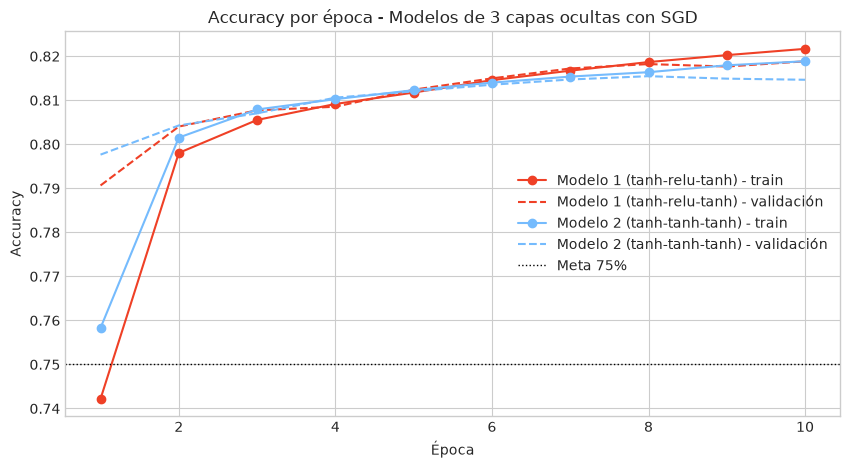

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 20)             │         1,540 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,403 (9.39 KB)

 Trainable params: 2,401 (9.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [10]:
def crear_modelo(activaciones, inicializaciones, neuronas=20):
    modelo = keras.Sequential([keras.Input(shape=(X_train_std.shape[1],))])
    for act, ini in zip(activaciones, inicializaciones):
        modelo.add(layers.Dense(neuronas, activation=act, use_bias=True,
                                kernel_initializer=ini, bias_initializer='zeros'))
    modelo.add(layers.Dense(1, activation='sigmoid', use_bias=True,
                            kernel_initializer='glorot_uniform', bias_initializer='zeros'))
    modelo.compile(optimizer=keras.optimizers.SGD(), loss='binary_crossentropy',
                   metrics=['accuracy'])
    return modelo

configuraciones = {
    'Modelo 1 (tanh-relu-tanh)': (['tanh', 'relu', 'tanh'],
                                  ['glorot_uniform', 'he_normal', 'glorot_uniform']),
    'Modelo 2 (tanh-tanh-tanh)': (['tanh', 'tanh', 'tanh'],
                                  ['glorot_uniform', 'glorot_uniform', 'glorot_uniform'])
}

historias, modelos_p3 = {}, {}
for nombre, (acts, inits) in configuraciones.items():
    keras.utils.set_random_seed(42)
    modelo = crear_modelo(acts, inits)
    historias[nombre] = modelo.fit(X_train_std, y_train, validation_split=0.2,
                                   epochs=10, batch_size=32, verbose=0)
    modelos_p3[nombre] = modelo
    acc_test = modelo.evaluate(X_test_std, y_test, verbose=0)[1]
    print(f'{nombre}: accuracy train = {historias[nombre].history["accuracy"][-1]:.4f} | '
          f'validación = {historias[nombre].history["val_accuracy"][-1]:.4f} | test = {acc_test:.4f}')

plt.figure(figsize=(10, 5))
for (nombre, h), color in zip(historias.items(), ['xkcd:tomato', 'xkcd:sky blue']):
    epocas = range(1, len(h.history['accuracy']) + 1)
    plt.plot(epocas, h.history['accuracy'], color=color, marker='o', label=f'{nombre} - train')
    plt.plot(epocas, h.history['val_accuracy'], color=color, ls='--', label=f'{nombre} - validación')
plt.axhline(0.75, color='black', lw=1, ls=':', label='Meta 75%')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Accuracy por época - Modelos de 3 capas ocultas con SGD')
plt.legend()
plt.show()

modelos_p3['Modelo 1 (tanh-relu-tanh)'].summary()

### Conclusión del paso 3

Ambos modelos (3 capas ocultas de 20 neuronas, optimizador SGD, 10 épocas) superan la meta de 75% de accuracy desde la segunda época. Los pesos se inicializaron con Glorot en las capas tanh y en la salida sigmoide, y con He en la capa ReLU, siguiendo la recomendación de la guía; los sesgos (uno por neurona) se inicializaron en cero.

| Modelo | Accuracy train | Validación | Test |
|---|---|---|---|
| 1 (tanh-relu-tanh) | 0.822 | 0.819 | **0.821** |
| 2 (tanh-tanh-tanh) | 0.819 | 0.815 | 0.818 |

El modelo 1 obtiene un desempeño levemente superior (0.3 puntos en test). El modelo 2 converge más rápido al inicio, pero su accuracy de validación se estanca desde la época 7, mientras el modelo 1 sigue mejorando hasta la época 10; la capa ReLU, que no satura en valores positivos, puede favorecer la propagación del gradiente. No hay sobreajuste en ninguno de los modelos (train y validación evolucionan juntos), y las curvas aún ascienden en la época 10, lo que sugiere que más épocas podrían mejorar ambos resultados.

4. Construye una red neuronal con regularización Dropout aplicando búsqueda de grilla
para tres fold. El modelo debe conseguir un accuracy superior al 80%. La búsqueda
debe sintonizar los siguientes hiper parámetros:
a. Cantidad de capas ocultas: de 3 o 4
b. Método de optimización: Adam o SGD
c. learning_rate: 0.03 y 0.06
d. Cantidad de neuronas en las capas ocultas: 20
e. Funciones de activación en las capas ocultas: tanh

4. Construye una red neuronal con regularización Dropout aplicando búsqueda de grilla
para tres fold. El modelo debe conseguir un accuracy superior al 80%. La búsqueda
debe sintonizar los siguientes hiper parámetros:
a. Cantidad de capas ocultas: de 3 o 4
b. Método de optimización: Adam o SGD
c. learning_rate: 0.03 y 0.06
d. Cantidad de neuronas en las capas ocultas: 20
e. Funciones de activación en las capas ocultas: tanh
f. Rate para Dropout: 0.001
g. Inicialización de los pesos: [glorot_normal, glorot_uniform]

Debes mostrar los hiper parámetros óptimos encontrados por la búsqueda de grilla.
Calcula además las métricas asociadas a la matriz de confusión al aplicar el
modelo con los hiper parámetros óptimos al conjunto de test. Muestra la curva ROC
para el mejor modelo incluyendo el AUC.


In [11]:
import time

def construir_red(n_capas=3, init='glorot_uniform', neuronas=20, activacion='tanh', dropout=0.001):
    modelo = keras.Sequential([keras.Input(shape=(X_train_std.shape[1],))])
    for _ in range(n_capas):
        modelo.add(layers.Dense(neuronas, activation=activacion,
                                kernel_initializer=init, bias_initializer='zeros'))
        modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(1, activation='sigmoid', kernel_initializer=init))
    return modelo

clf_red = KerasClassifier(
    model=construir_red,
    loss='binary_crossentropy',
    optimizer='sgd',
    optimizer__learning_rate=0.03,
    epochs=10,
    batch_size=32,
    verbose=0,
    random_state=42
)

grilla_red = {
    'model__n_capas': [3, 4],
    'optimizer': ['adam', 'sgd'],
    'optimizer__learning_rate': [0.03, 0.06],
    'model__neuronas': [20],
    'model__activacion': ['tanh'],
    'model__dropout': [0.001],
    'model__init': ['glorot_normal', 'glorot_uniform']
}

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

inicio = time.time()
grid_red = GridSearchCV(clf_red, grilla_red, cv=cv3, scoring='accuracy', n_jobs=1, verbose=1)
grid_red.fit(X_train_std, y_train)
print(f'Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} minutos')

print('Mejores hiperparámetros:', grid_red.best_params_)
print(f'Mejor accuracy en validación cruzada: {grid_red.best_score_:.4f}')

res = pd.DataFrame(grid_red.cv_results_)
cols = ['param_model__n_capas', 'param_optimizer', 'param_optimizer__learning_rate',
        'param_model__init', 'mean_test_score', 'std_test_score']
res[cols].sort_values('mean_test_score', ascending=False).round(4)

Fitting 3 folds for each of 16 candidates, totalling 48 fits


E0000 00:00:1792940055.073197  129031 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1792940079.321229  129031 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Tiempo de búsqueda: 22.3 minutos
Mejores hiperparámetros: {'model__activacion': 'tanh', 'model__dropout': 0.001, 'model__init': 'glorot_uniform', 'model__n_capas': 4, 'model__neuronas': 20, 'optimizer': 'sgd', 'optimizer__learning_rate': 0.06}
Mejor accuracy en validación cruzada: 0.8215


,param_model__n_capas,param_optimizer,param_optimizer__learning_rate,param_model__init,mean_test_score,std_test_score
15,4,sgd,0.06,glorot_uniform,0.8215,0.0031
11,3,sgd,0.06,glorot_uniform,0.8196,0.0012
7,4,sgd,0.06,glorot_normal,0.8189,0.0032
3,3,sgd,0.06,glorot_normal,0.8183,0.0014
14,4,sgd,0.03,glorot_uniform,0.8175,0.0041
10,3,sgd,0.03,glorot_uniform,0.8175,0.0022
2,3,sgd,0.03,glorot_normal,0.8165,0.0039
6,4,sgd,0.03,glorot_normal,0.8164,0.0019
0,3,adam,0.03,glorot_normal,0.7868,0.0008
8,3,adam,0.03,glorot_uniform,0.7856,0.0081


In [13]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

Matriz de confusión en test (filas = real, columnas = predicho):
                     Pred 0  Pred 1
Real 0 (no cancela)   22974    1830
Real 1 (cancela)       4856    9737

Métricas derivadas de la matriz de confusión:
Accuracy                           0.8303
Precision (clase 1)                0.8418
Recall / Sensibilidad (clase 1)    0.6672
Especificidad (clase 0)            0.9262
F1-score (clase 1)                 0.7444
dtype: float64

               precision    recall  f1-score   support

           0      0.826     0.926     0.873     24804
           1      0.842     0.667     0.744     14593

    accuracy                          0.830     39397
   macro avg      0.834     0.797     0.809     39397
weighted avg      0.832     0.830     0.825     39397



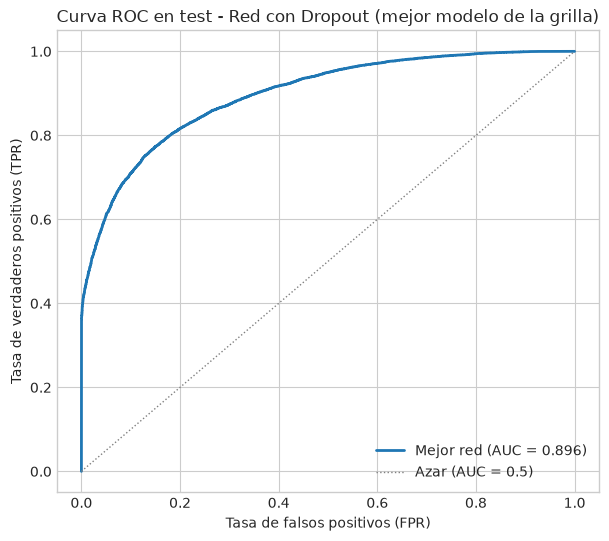

In [14]:
mejor_red = grid_red.best_estimator_
yhat_test = mejor_red.predict(X_test_std)
proba_test = mejor_red.predict_proba(X_test_std)[:, 1]

cm = confusion_matrix(y_test, yhat_test)
tn, fp, fn, tp = cm.ravel()
print('Matriz de confusión en test (filas = real, columnas = predicho):')
print(pd.DataFrame(cm, index=['Real 0 (no cancela)', 'Real 1 (cancela)'],
                   columns=['Pred 0', 'Pred 1']))

metricas = pd.Series({
    'Accuracy': (tp + tn) / cm.sum(),
    'Precision (clase 1)': tp / (tp + fp),
    'Recall / Sensibilidad (clase 1)': tp / (tp + fn),
    'Especificidad (clase 0)': tn / (tn + fp),
    'F1-score (clase 1)': 2 * tp / (2 * tp + fp + fn)
})
print('\nMétricas derivadas de la matriz de confusión:')
print(metricas.round(4))
print('\n', classification_report(y_test, yhat_test, digits=3))

auc_red = roc_auc_score(y_test, proba_test)
fpr, tpr, _ = roc_curve(y_test, proba_test)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, lw=2, label=f'Mejor red (AUC = {auc_red:.3f})')
plt.plot([0, 1], [0, 1], color='gray', ls=':', lw=1, label='Azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.title('Curva ROC en test - Red con Dropout (mejor modelo de la grilla)')
plt.legend(loc='lower right')
plt.show()

### Desempeño del mejor modelo en test

| Métrica | Valor |
|---|---|
| Accuracy | 0.830 |
| Precision (clase 1) | 0.842 |
| Recall / Sensibilidad (clase 1) | 0.667 |
| Especificidad (clase 0) | 0.926 |
| F1-score (clase 1) | 0.744 |
| AUC | 0.897 |

El modelo alcanza 83.0% de accuracy en test, superando la meta de 80% y confirmando el resultado de la validación cruzada (82.2%). La matriz de confusión muestra un modelo conservador: alta especificidad (92.6%; 1.830 falsas alarmas entre 24.804 reservas no canceladas) y alta precision (84.2%), pero un recall moderado (66.7%): de las 14.593 cancelaciones reales, no detecta 4.856. Con un 63% de reservas no canceladas, el modelo tiende a predecir "no cancela" ante la duda. El AUC de 0.897 indica una buena capacidad para ordenar las reservas por riesgo, por lo que ajustar el umbral de decisión permitiría priorizar recall o precision según el uso: una alta precision es preferible para decisiones de sobreventa (overbooking), mientras que un mayor recall convendría para acciones preventivas como contactar a los clientes en riesgo.

5. Del conjunto original (sin los valores excluidos) escoge al azar cinco observaciones
en que “deposit_type_Non Refund” sea cero, y con esto realiza una predicción
usando el mejor modelo encontrado por la búsqueda de grilla anterior. Comenta los
resultados.

In [15]:
candidatos = X_test[X_test['deposit_type_Non Refund'] == 0]
print(f'Reservas de test sin "Non Refund": {len(candidatos)} '
      f'(tasa de cancelación real: {y_test.loc[candidatos.index].mean():.3f})')

muestra = candidatos.sample(5, random_state=42)
muestra_std = pd.DataFrame(scaler.transform(muestra), columns=X.columns, index=muestra.index)

resultado = df.loc[muestra.index, ['hotel', 'lead_time', 'market_segment', 'deposit_type',
                                   'total_of_special_requests', 'required_car_parking_spaces', 'adr']].copy()
resultado['prob_cancelacion'] = mejor_red.predict_proba(muestra_std)[:, 1].round(3)
resultado['prediccion'] = mejor_red.predict(muestra_std)
resultado['real'] = y_test.loc[muestra.index]
resultado['acierto'] = resultado['prediccion'] == resultado['real']
print(resultado.to_string())

candidatos_std = pd.DataFrame(scaler.transform(candidatos), columns=X.columns, index=candidatos.index)
acc_sub = (mejor_red.predict(candidatos_std) == y_test.loc[candidatos.index]).mean()
print(f'\nAccuracy en todas las reservas de test sin "Non Refund": {acc_sub:.4f}')

Reservas de test sin "Non Refund": 34652 (tasa de cancelación real: 0.285)
              hotel  lead_time market_segment deposit_type  total_of_special_requests  required_car_parking_spaces     adr  prob_cancelacion  prediccion  real  acierto
19792  Resort Hotel          3  Offline TA/TO   No Deposit                          0                            0   46.00             0.076           0     0     True
21445  Resort Hotel          4  Offline TA/TO   No Deposit                          1                            0   75.00             0.280           0     0     True
16456  Resort Hotel         58      Online TA   No Deposit                          0                            1  170.33             0.004           0     0     True
71867    City Hotel         23      Online TA   No Deposit                          0                            0  192.00             0.621           1     1     True
65942    City Hotel        295      Online TA   No Deposit                          0

### Predicción sobre cinco reservas sin depósito "Non Refund"

Se seleccionaron al azar cinco reservas del conjunto de test (datos que el modelo no vio durante el entrenamiento) con `deposit_type_Non Refund` = 0, y se estandarizaron con el escalador ajustado en entrenamiento. El modelo acertó las cinco:

- La reserva con estacionamiento solicitado recibe una probabilidad casi nula (0.004), coherente con que ninguna reserva con estacionamiento fue cancelada.
- Las dos reservas del Resort Hotel con muy poca anticipación (3 y 4 días) reciben probabilidades bajas (0.076 y 0.280); la segunda incluye además un pedido especial.
- Las dos reservas canceladas, del City Hotel por canal online sin pedidos especiales, reciben probabilidades altas: 0.742 para la reservada con 295 días de anticipación y 0.621 para la de tarifa alta, el caso más cercano al umbral.

Las predicciones son coherentes con las variables identificadas como relevantes en el análisis descriptivo. Dado que cinco observaciones son insuficientes para evaluar el modelo (con 81% de accuracy, acertar 5 de 5 ocurre por azar en ~34% de los casos), se evaluó además todo el subconjunto de test sin "Non Refund" (34.652 reservas, 28.5% canceladas): el accuracy es de 0.807, menor que el 0.830 general porque se excluyen las reservas "Non Refund", canceladas en un 99.4% y fáciles de predecir, pero aún superior a 80%.

## Conclusión final

**Objetivo:** predecir la cancelación de reservas en un hotel urbano y uno turístico mediante redes neuronales multicapa con distintas activaciones, inicializaciones y regularización Dropout, sintonizadas con búsqueda de grilla.

### Preparación de los datos
- Se descartaron las 7 columnas indicadas, entre ellas `reservation_status`, que coincide exactamente con la variable objetivo (fuga de información). Se eliminaron 4 registros con ausentes en `children` (< 4%).
- Variables más relacionadas con la cancelación: **deposit_type** ("Non Refund" cancela el 99.4%), **lead_time** (mediana de 113 vs 45 días), **total_of_special_requests**, **required_car_parking_spaces** (0% de cancelación con estacionamiento) y **market_segment** ("Groups" cancela el 61%).
- `adr` discrimina poco entre clases. Tenía 3.793 outliers por arriba y 0 por abajo: se eliminaron los 3 más extremos (5.400, 510, 508) y una tarifa negativa imposible, y el resto se reemplazó por el promedio.
- Se crearon 60 variables dummies (76 en total), se dividió la muestra de forma estratificada (67/33) y se estandarizó con los parámetros del entrenamiento.

### Redes con tres capas ocultas (SGD, 10 épocas)
Ambas superan la meta de 75%: tanh-relu-tanh obtuvo 0.821 en test y tanh-tanh-tanh 0.818. Los pesos se inicializaron con Glorot en capas tanh y salida sigmoide, y con He en la capa ReLU, siguiendo la recomendación de la guía.

### Red con Dropout y búsqueda de grilla
- La mejor combinación (4 capas, SGD, learning_rate 0.06, glorot_uniform) obtuvo 0.8215 en validación cruzada y **0.830 en test**, superando la meta de 80%, con **AUC de 0.897**.
- El optimizador fue el factor decisivo: SGD superó a Adam en todas las combinaciones, porque los learning_rate de la grilla (0.03 y 0.06) son 30 a 60 veces mayores que el valor habitual de Adam (0.001). El número de capas y el tipo de inicialización Glorot tuvieron efectos menores.
- El modelo es conservador: alta especificidad (0.926) y precision (0.842), pero recall moderado (0.667). El umbral de decisión debería ajustarse según el uso: overbooking (priorizar precision) o retención preventiva (priorizar recall).
- En el subconjunto sin "Non Refund", el accuracy es de 0.807; las predicciones individuales son coherentes con las variables relevantes del análisis.

### Limitaciones
- **Fugas de información potenciales:** `assigned_room_type` se registra en el check-in (las reservas canceladas casi no tienen cambios de habitación) y `required_car_parking_spaces` podría registrarse al llegar al hotel. Ambas se mantuvieron por estar en el enunciado, pero podrían inflar el desempeño respecto de un uso real al momento de reservar.
- **Duplicados:** el 28.5% de los registros son idénticos tras descartar columnas, probablemente reservas de grupo; una reserva y su "gemela" pueden quedar en train y test, lo que puede inflar levemente las métricas.
- **Dropout de 0.001:** apaga en promedio 1 de cada 1.000 neuronas, por lo que su efecto regularizador es prácticamente nulo; valores entre 0.1 y 0.5 serían más adecuados. Al estar fijo en la grilla, su efecto no pudo evaluarse.
-